# Tier 2: Monte Carlo, hands on

Tier 1 priced an option with a formula. This notebook prices the same option a second way: by
**simulating** thousands of possible futures for the stock, computing the option's payoff in
each one, and averaging. If the simulation is right, the average lands on the Tier 1 price.

Most options (Tier 5: Asian, barrier, Heston) have no formula, and simulation still works for
them. Tier 2 builds the method on a case where the right answer is known, and every number can be
checked against it.

Units: `r`, `q` and `sigma` are yearly and continuously compounded, `T` is in years. The running
example is hull's call: S = 42, K = 40, T = 0.5, r = 10%, σ = 20%, worth **4.7594**.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm, qmc

from ope import call_price, gbm_terminal, greeks, mc_delta, mc_price
from ope.monte_carlo import payoff
from ope.plots import plot_mc_convergence

S, K, T, r, sigma = 42.0, 40.0, 0.5, 0.10, 0.20
exact = float(call_price(S, K, T, r, sigma))
print(f"closed form (Tier 1): {exact:.4f}")

closed form (Tier 1): 4.7594


## 1. One simulated future, step by step

Black-Scholes says the stock price at expiry is

$$S_T = S \cdot e^{(r - \frac{1}{2}\sigma^2)T + \sigma\sqrt{T}\,Z}$$

where $Z$ is a random number from the bell curve (average 0, standard deviation 1). Reading it:

- $(r - \frac{1}{2}\sigma^2)T$ is the growth: the stock grows at $r$ in the pricing world. The
  $-\frac{1}{2}\sigma^2$ corrects for the lopsided shape of the curve, so that the **average**
  $S_T$ is $S e^{rT}$.
- $\sigma\sqrt{T}\,Z$ is the luck: how far this particular future lands from the typical one.

This is `gbm_terminal`, the "try it yourself" function of this tier. One future, by hand:

In [2]:
z = 0.5  # a draw a bit above average
growth = (r - 0.5 * sigma**2) * T
luck = sigma * math.sqrt(T) * z
s_t = S * math.exp(growth + luck)
print(f"growth = {growth:.4f}, luck = {luck:.4f}, S_T = {s_t:.4f}")
print(f"gbm_terminal gives {float(gbm_terminal(S, T, r, sigma, z)[()]):.4f}")
print(f"payoff of the call in this future: max(S_T - K, 0) = {max(s_t - K, 0):.4f}")

growth = 0.0400, luck = 0.0707, S_T = 46.9170
gbm_terminal gives 46.9170
payoff of the call in this future: max(S_T - K, 0) = 6.9170


## 2. Many futures

Below, 40 possible paths of the stock over the 6 months (drawn in small steps only to show
them; the pricer jumps straight to the end), and the histogram of 100,000 final prices. The
histogram matches the lognormal curve Black-Scholes predicts. The shaded part, above the strike,
is where the call pays.

In [3]:
rng = np.random.default_rng(0)
steps, dt = 126, T / 126
z_paths = rng.standard_normal((40, steps))
log_paths = np.cumsum((r - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt) * z_paths, axis=1)
paths = S * np.exp(np.hstack([np.zeros((40, 1)), log_paths]))

s_end = gbm_terminal(S, T, r, sigma, np.random.default_rng(1).standard_normal(100_000))
grid = np.linspace(25, 65, 400)
mean_log, sd_log = math.log(S) + (r - 0.5 * sigma**2) * T, sigma * math.sqrt(T)
density = norm.pdf((np.log(grid) - mean_log) / sd_log) / (grid * sd_log)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(np.linspace(0, T, steps + 1), paths.T, lw=0.8, alpha=0.7)
a1.axhline(K, color="black", ls="--", label="strike K = 40")
a1.set_xlabel("time (years)")
a1.set_ylabel("stock price")
a1.set_title("40 simulated paths")
a1.legend()
a2.hist(s_end, bins=120, range=(25, 65), density=True, alpha=0.5, label="100,000 simulated S_T")
a2.plot(grid, density, color="black", label="lognormal curve (theory)")
a2.fill_between(
    grid[grid > K], density[grid > K], alpha=0.45, color="tab:orange", label="call pays"
)
a2.set_xlabel("stock price at expiry S_T")
a2.set_title("where the stock ends")
a2.legend(loc="upper right")
plt.show()
print(f"share of futures where the call pays: {np.mean(s_end > K):.4f}")
print(f"N(d2) from Tier 1, the same probability:   {norm.cdf(0.6278):.4f}")

share of futures where the call pays: 0.7340
N(d2) from Tier 1, the same probability:   0.7349


## 3. Price = average discounted payoff

The Monte Carlo price is the average payoff over all simulated futures, converted to today's
money with $e^{-rT}$. Since it's an average of random numbers, it has an error. The **standard
error** measures it: the spread of the payoffs divided by $\sqrt{N}$, where $N$ is the number of
paths. The **95% confidence interval** is the estimate ± 1.96 standard errors: it holds the true
price in 95% of runs.

`mc_price` computes it:

In [4]:
for n in (1_000, 10_000, 100_000, 1_000_000):
    res = mc_price("call", S, K, T, r, sigma, n_paths=n, rng=42)
    lo, hi = res.ci95
    line = f"N = {n:>9,}  price {res.estimate:.4f}  std error {res.std_error:.4f}"
    print(f"{line}  95% CI [{lo:.4f}, {hi:.4f}]")
print(f"closed form       {exact:.4f}")

N =     1,000  price 4.6183  std error 0.1518  95% CI [4.3207, 4.9159]
N =    10,000  price 4.7280  std error 0.0497  95% CI [4.6307, 4.8254]
N =   100,000  price 4.7463  std error 0.0157  95% CI [4.7154, 4.7771]
N = 1,000,000  price 4.7603  std error 0.0050  95% CI [4.7506, 4.7701]
closed form       4.7594


## 4. Why the error shrinks like 1/√N

Each time you multiply the paths by 100, the error shrinks by 10, the square root of 100: the
standard error is $\sigma_{payoff} / \sqrt{N}$. On a log-log chart it's a straight line of
slope −1/2. The orange line uses the two variance-reduction tricks of sections 6 and 7: same
slope, but much lower.

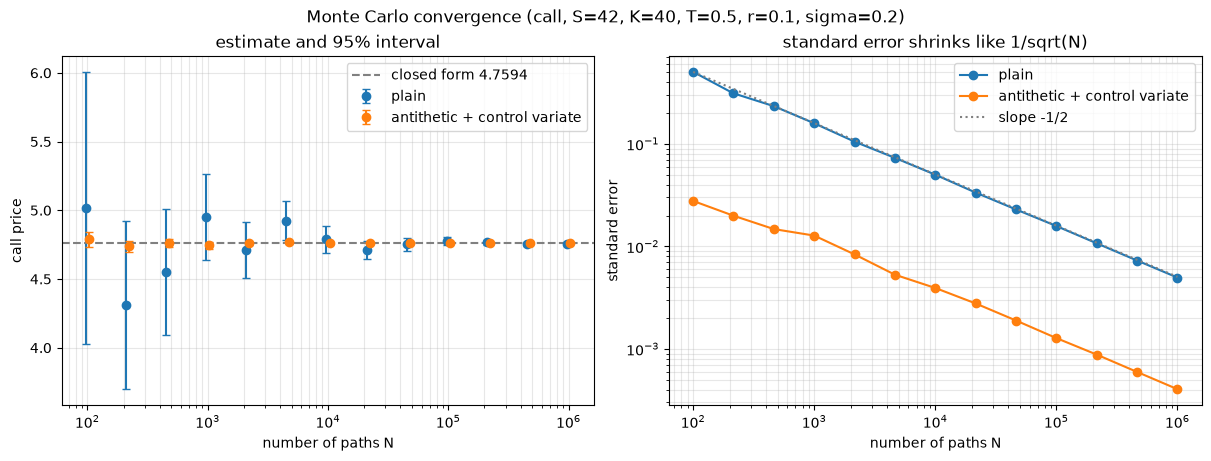

In [5]:
plot_mc_convergence("call", S, K, T, r, sigma)

## 5. Does "95%" really mean 95%?

One run can miss: a 95% interval is wrong 1 time in 20, by design. Below, 100 independent runs of
4,000 paths, each with its interval. The ones that miss the true price are in red. Over 100
runs we expect about 5, but the count itself is random: anything from about 1 to 10 is
normal for 100 runs. Exercise 3 below runs more.

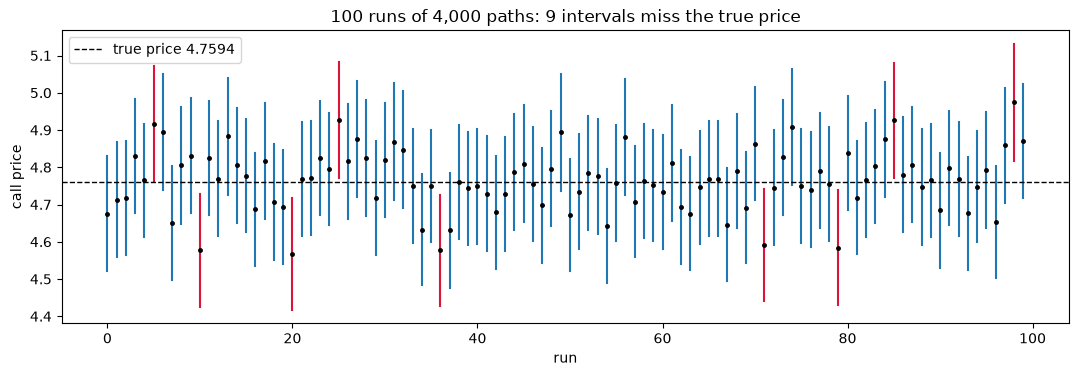

In [6]:
runs = [mc_price("call", S, K, T, r, sigma, n_paths=4_000, rng=seed) for seed in range(100)]
fig, ax = plt.subplots(figsize=(13, 3.8))
misses = 0
for i, res in enumerate(runs):
    lo, hi = res.ci95
    miss = not lo <= exact <= hi
    misses += miss
    ax.plot([i, i], [lo, hi], color="crimson" if miss else "tab:blue", lw=1.5)
    ax.plot(i, res.estimate, "o", ms=2.5, color="black")
ax.axhline(exact, color="black", ls="--", lw=1, label=f"true price {exact:.4f}")
ax.set_xlabel("run")
ax.set_ylabel("call price")
ax.set_title(f"100 runs of 4,000 paths: {misses} intervals miss the true price")
ax.legend()
plt.show()

## 6. Antithetic variates: pair every future with its mirror

For every random draw $Z$, also use $-Z$. If one future is unusually lucky, its mirror is
unusually unlucky, and their average is closer to the truth. A path and its mirror are
**dependent**: the standard error comes from the pair averages, and treating the $N$ payoffs as
independent would report an error that is too small.

## 7. Control variate: correct with something we already know

The discounted stock price $e^{-rT}S_T$ has a known average: $S$ today. When a simulation
happens to produce stocks that are too high on average, the call payoffs are too high as well.
We measure the simulation's error on the stock and remove the matching amount from the price:

$$\text{price}_{cv} = \overline{X} - \beta\,(\overline{Y} - S)$$

where $X$ is the discounted payoff, $Y$ the discounted stock, and $\beta$ the slope of $X$
against $Y$ (a regression). The scatter shows why it works so well for a call: payoff and stock
move together.

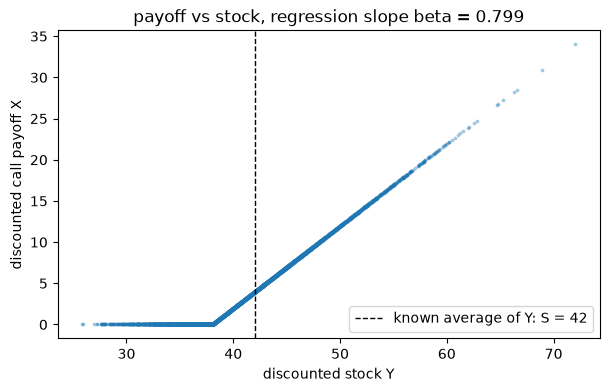

method                              price  std error  error cut
plain                              4.7604    0.01109       1.0x
antithetic                         4.7547    0.00547       2.0x
control variate                    4.7566    0.00306       3.6x
antithetic + control variate       4.7588    0.00090      12.3x


In [7]:
z = np.random.default_rng(3).standard_normal(5_000)
s_t = gbm_terminal(S, T, r, sigma, z)
x = math.exp(-r * T) * payoff("call", s_t, K)
y = math.exp(-r * T) * s_t
beta = np.cov(x, y)[0, 1] / np.var(y, ddof=1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(y, x, s=3, alpha=0.3)
ax.axvline(S, color="black", ls="--", lw=1, label="known average of Y: S = 42")
ax.set_xlabel("discounted stock Y")
ax.set_ylabel("discounted call payoff X")
ax.set_title(f"payoff vs stock, regression slope beta = {beta:.3f}")
ax.legend()
plt.show()

print(f"{'method':32s} {'price':>8s} {'std error':>10s} {'error cut':>10s}")
plain = mc_price("call", S, K, T, r, sigma, n_paths=200_000, rng=7).std_error
for name, anti, cv in [
    ("plain", False, False),
    ("antithetic", True, False),
    ("control variate", False, True),
    ("antithetic + control variate", True, True),
]:
    res = mc_price(
        "call", S, K, T, r, sigma, n_paths=200_000, antithetic=anti, control_variate=cv, rng=7
    )
    print(f"{name:32s} {res.estimate:8.4f} {res.std_error:10.5f} {plain / res.std_error:9.1f}x")

Same number of paths, standard error cut by about 2x, 3.6x and 12x. Since the error shrinks
like $1/\sqrt{N}$, a 12x cut is worth about 150 times more paths.

## 8. Delta by Monte Carlo, three ways

Delta is how much the price moves when the stock moves by 1. Three ways to estimate it:

- **Bump and reprice**: price at $S+h$ and $S-h$ with the **same** random draws (common random
  numbers), take the slope. Reusing the draws makes the noise cancel.
- **Pathwise**: differentiate each path's payoff directly. For a call, a path pays
  $S_T - K$ above the strike, and $S_T$ moves with $S$ in proportion, so its slope is
  $e^{-rT} \cdot 1_{S_T>K} \cdot S_T/S$.
- **Likelihood ratio**: keep the payoff as it is, and weight it by how a change in $S$ changes the
  probability of each future: $e^{-rT} \cdot \text{payoff} \cdot Z / (S\sigma\sqrt{T})$. It
  works even for payoffs that jump (Tier 5), but it's noisier.

closed form delta: 0.7791
bump              0.7789  std error 0.00105
pathwise          0.7789  std error 0.00107
likelihood_ratio  0.7841  std error 0.00367


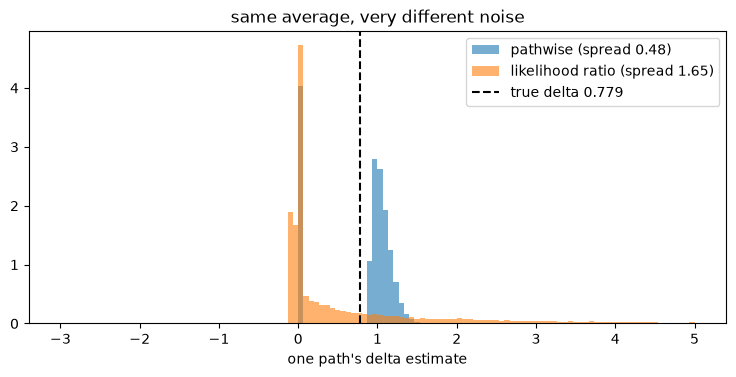

In [8]:
exact_delta = float(greeks("call", S, K, T, r, sigma).delta)
print(f"closed form delta: {exact_delta:.4f}")
for m in ("bump", "pathwise", "likelihood_ratio"):
    res = mc_delta("call", S, K, T, r, sigma, method=m, n_paths=200_000, rng=5)
    print(f"{m:17s} {res.estimate:.4f}  std error {res.std_error:.5f}")

z = np.random.default_rng(9).standard_normal(20_000)
s_t = gbm_terminal(S, T, r, sigma, z)
disc = math.exp(-r * T)
pathwise = disc * (s_t > K) * s_t / S
lr = disc * payoff("call", s_t, K) * z / (S * sigma * math.sqrt(T))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(
    pathwise,
    bins=120,
    range=(-3, 5),
    alpha=0.6,
    density=True,
    label=f"pathwise (spread {pathwise.std():.2f})",
)
ax.hist(
    lr,
    bins=120,
    range=(-3, 5),
    alpha=0.6,
    density=True,
    label=f"likelihood ratio (spread {lr.std():.2f})",
)
ax.axvline(exact_delta, color="black", ls="--", label=f"true delta {exact_delta:.3f}")
ax.set_xlabel("one path's delta estimate")
ax.set_title("same average, very different noise")
ax.legend()
plt.show()

## 9. Optional: Sobol points instead of random numbers

Pseudo-random draws clump and leave gaps by chance. **Sobol** points are spread out on purpose,
so they cover the bell curve more evenly. The error then shrinks closer to $1/N$ than to
$1/\sqrt{N}$. The usual standard error formula no longer applies (the points aren't
independent), so here the error is measured directly against the true price, over 16 scrambled
Sobol sets and 16 random seeds.

In [9]:
ns = 2 ** np.arange(8, 17)
disc = math.exp(-r * T)
rmse_random, rmse_sobol = [], []
for n in ns:
    err_r, err_s = [], []
    for seed in range(16):
        z_r = np.random.default_rng(seed).standard_normal(n)
        u = qmc.Sobol(d=1, scramble=True, seed=seed).random(n).ravel()
        z_s = norm.ppf(u)
        for zz, errs in ((z_r, err_r), (z_s, err_s)):
            est = disc * payoff("call", gbm_terminal(S, T, r, sigma, zz), K).mean()
            errs.append(est - exact)
    rmse_random.append(np.sqrt(np.mean(np.square(err_r))))
    rmse_sobol.append(np.sqrt(np.mean(np.square(err_s))))

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(ns, rmse_random, "o-", label="pseudo-random")
ax.loglog(ns, rmse_sobol, "o-", label="scrambled Sobol")
ax.loglog(ns, rmse_random[0] * np.sqrt(ns[0] / ns), ":", color="gray", label="slope -1/2")
ax.loglog(ns, rmse_sobol[0] * ns[0] / ns, "--", color="gray", label="slope -1")
ax.set_xlabel("number of points N")
ax.set_ylabel("typical error vs the true price")
ax.set_title("Sobol points converge faster")
ax.legend()
plt.show()
print(f"at N = {ns[-1]:,}: random error {rmse_random[-1]:.5f}, Sobol error {rmse_sobol[-1]:.5f}")

at N = 65,536: random error 0.01924, Sobol error 0.00004


## 10. Try it yourself

1. Write your own `gbm_terminal` in the cell below with `math.exp` and `math.sqrt`, and check it
   against `ope.gbm_terminal` for a few values of `z`.
2. Price hull's **put** (true price 0.8086) with `mc_price`. Which variance-reduction trick helps
   most for a put? Why might the control variate help less?
3. Run section 5 with 400 runs instead of 100. How close to 5% do the misses get?

In [10]:
# your gbm_terminal here, compare w/ gbm_terminal(42, 0.5, 0.10, 0.20, z)